Project question: Can we identify locations coca plantations in Colombia using satellite imagery?

Study area: Colombia

Time period: 2026, but using training data from many previous years. 

Main raster dataset: Sentinel 2 

Provider: European Space Agency/Planetary Computer

Access route: Planetary Computer

Search criteria:

Useful assets or bands: All of the spectral bands to identify the coca spectral signature

Expected output: Satellite image of colombia or small part of colombia

Main limitation: Resolution, is it detailed enough to look be able to separate the vegetation types. 



Main vector/context dataset: SIMCI coca plantation data

Provider: Colombian government and UN

Access route: Colombian government through an API

Role in project: Gives me locations of coca plantations that I can then pair to satellite data to have labelled satellite data for my model to train on

Main limitation: The data does not consist of actual polygons of known coca plantations but of their estimates of coca plantations in a 1km2 area. **I could use different data sources instead, for example coca in peru or opium in afghanistan/myanmar**.

Small test: Getting satellite TIFF

What I tested:

What worked:

What did not work:

Next decision:

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from pyproj import Transformer
from rasterio.windows import from_bounds
from rasterio.windows import transform as window_transform


def bbox_to_dataset_crs(bbox_wgs84, dst_crs):
    """Transform a WGS84 bounding box to a raster's native CRS.

    Rasterio windows must be given in the source file's own CRS, not WGS84.

    Args:
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        dst_crs: Target CRS (e.g., src.crs from rasterio.open()).

    Returns:
        Bounding box in the target CRS [min_x, min_y, max_x, max_y].
    """
    transformer = Transformer.from_crs("EPSG:4326", dst_crs, always_xy=True)
    min_lon, min_lat, max_lon, max_lat = bbox_wgs84
    xs, ys = transformer.transform([min_lon, max_lon], [min_lat, max_lat])
    return min(xs), min(ys), max(xs), max(ys)


def ycbcr_to_rgb(stack):
    """Convert a 3-band YCbCr image (ITU-R BT.601) to RGB uint8.

    Some imagery (e.g. JPEG-compressed GeoTIFFs, as used by SWISSIMAGE) stores
    colour as YCbCr rather than RGB, and must be converted before it can be
    written or plotted as a normal RGB image.

    Args:
        stack: Array of shape (3, height, width) with YCbCr bands.

    Returns:
        RGB array of shape (3, height, width) as uint8.
    """
    y, cb, cr = stack.astype("float32")
    r = y + 1.402 * (cr - 128.0)
    g = y - 0.344136 * (cb - 128.0) - 0.714136 * (cr - 128.0)
    b = y + 1.772 * (cb - 128.0)
    return np.clip(np.stack([r, g, b]), 0, 255).astype("uint8")


def save_single_asset_subset(
    item, asset_key, bbox_wgs84, output_path, band_indexes=(1, 2, 3)
):
    """Read the AOI window from one raster asset and save it as a GeoTIFF.

    Output pixel dimensions follow the AOI at the source's native resolution,
    so a landscape bbox produces a landscape image (no separate width/height
    arguments needed).

    Args:
        item: A STAC Item object.
        asset_key: String key of the asset to read (e.g., 'B02', 'red', 'image').
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        output_path: File path for the output GeoTIFF.
        band_indexes: Tuple of band indices to read (1-indexed; default (1,2,3) for RGB).

    Returns:
        Path to the written GeoTIFF file.
    """
    href = item.assets[asset_key].href

    with rasterio.open(href) as src:
        print("Source CRS:", src.crs)
        bounds = bbox_to_dataset_crs(bbox_wgs84, src.crs)
        window = from_bounds(*bounds, transform=src.transform)

        stack = src.read(
            list(band_indexes), window=window, boundless=True, fill_value=0
        )
        print("Read shape, dtype:", stack.shape, stack.dtype)

        profile = src.profile.copy()
        profile.update(
            driver="GTiff",
            height=stack.shape[1],
            width=stack.shape[2],
            count=len(band_indexes),
            transform=window_transform(window, src.transform),
            compress="deflate",
        )
        profile.pop("photometric", None)

        if (
            str(src.profile.get("photometric", "")).lower() == "ycbcr"
            and stack.shape[0] == 3
        ):
            print("Converting YCbCr -> RGB")
            stack = ycbcr_to_rgb(stack)
        profile.update(dtype=str(stack.dtype))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(stack)

    size_mb = output_path.stat().st_size / 1_000_000
    print(f"Saved: {output_path} ({size_mb:.2f} MB)")
    return output_path


def save_multiband_subset(item, asset_keys, bbox_wgs84, output_path):
    """Read the AOI window from several single-band assets and save as one GeoTIFF.

    Each asset key is read separately (one band each) and stacked in the given
    order, e.g. asset_keys=['B04', 'B03', 'B02'] for a red-green-blue stack.
    Output pixel dimensions follow the AOI at the source's native resolution.

    Args:
        item: A STAC Item object.
        asset_keys: Ordered list of asset keys, one per output band.
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        output_path: File path for the output GeoTIFF.

    Returns:
        Path to the written GeoTIFF file.
    """
    bands = []
    profile = None

    for key in asset_keys:
        with rasterio.open(item.assets[key].href) as src:
            bounds = bbox_to_dataset_crs(bbox_wgs84, src.crs)
            window = from_bounds(*bounds, transform=src.transform)
            band = src.read(1, window=window, boundless=True, fill_value=0)
            bands.append(band)

            if profile is None:
                profile = src.profile.copy()
                profile.update(
                    driver="GTiff",
                    height=band.shape[0],
                    width=band.shape[1],
                    count=len(asset_keys),
                    transform=window_transform(window, src.transform),
                    compress="deflate",
                )
                profile.pop("photometric", None)

    stack = np.stack(bands)
    profile.update(dtype=str(stack.dtype))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(stack)

    size_mb = output_path.stat().st_size / 1_000_000
    print(f"Saved: {output_path} ({size_mb:.2f} MB)")
    return output_path


def stretch_rgb(rgb):
    """Apply a percentile stretch to an RGB image for better visual contrast.

    Raw satellite data often spans a wide dynamic range. A 2-98 percentile stretch clips
    extreme values and maps the middle 96% to the display range, improving visibility of
    detail without losing important information to saturation.

    Args:
        rgb: Array of shape (3, height, width) or (height, width, 3).

    Returns:
        Stretched array normalized to [0, 1].
    """
    rgb = np.moveaxis(rgb, 0, -1).astype("float32")
    p_low, p_high = np.nanpercentile(rgb, (2, 98))
    if p_high == p_low:
        return np.zeros_like(rgb)
    rgb = (rgb - p_low) / (p_high - p_low)
    return np.clip(rgb, 0, 1)


def plot_rgb(path, title):
    """Load a GeoTIFF and display it as an RGB image with percentile stretch.

    Args:
        path: File path to a 3-band GeoTIFF.
        title: Title for the plot.
    """
    with rasterio.open(path) as src:
        rgb = src.read([1, 2, 3])
    plt.figure(figsize=(7, 3))
    plt.imshow(stretch_rgb(rgb))
    plt.title(title)
    plt.axis("off")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


In [7]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

thuringia_bbox = [11.101685,50.519275,11.640015,50.735456]
# WGS84 lon/lat somewhere in southern Colombia

search = pc_catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=thuringia_bbox,
    datetime="2025-06-01/2025-08-31",
    query={"eo:cloud_cover": {"lt": 20}},
    max_items=10,
)

items = list(search.items())
print(f"Found {len(items)} Sentinel-2 item(s)")

Found 10 Sentinel-2 item(s)


In [8]:
items_sorted = sorted(
    items,
    key=lambda item: item.properties.get("eo:cloud_cover", 999),
)

s2_item = pc.sign(items_sorted[0])

print("Selected item:", s2_item.id)
print("Date:", s2_item.datetime)
print("Cloud cover:", round(s2_item.properties.get("eo:cloud_cover"), 2))

print("\nUseful assets:")
for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
    if key in s2_item.assets:
        print(key, "-", s2_item.assets[key].title)

Selected item: S2C_MSIL2A_20250701T101051_R022_T32UPA_20250701T154416
Date: 2025-07-01 10:10:51.025000+00:00
Cloud cover: 0.0

Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image


Saved: data/raw/sentinel2/s2_thuriginia_rgb_subset.tif (0.07 MB)


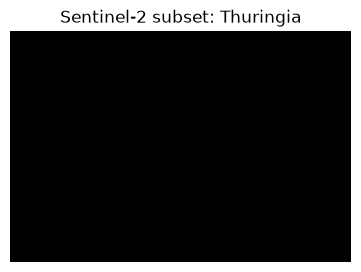

In [11]:
s2_subset = save_multiband_subset(
    item=s2_item,
    asset_keys=["B04", "B03", "B02"],  # red, green, blue
    bbox_wgs84=thuringia_bbox,
    output_path="data/raw/sentinel2/s2_thuriginia_rgb_subset.tif",
)

plot_rgb(s2_subset, "Sentinel-2 subset: Thuringia")

### Trying to add Vector Data: The EuroCropsML dataset

This dataset contains vector polygons labelled with crop classification and sentinel 2 band values. It is already ready for a ML workflow.

#### Lets try and import the geojson file for Estonia

In [14]:
from pathlib import Path
import geopandas as gpd

data_path = Path("../data/raw/vectors/raw_data/geometries/Estonia.geojson")

gdf = gpd.read_file(data_path)

gdf.head()

,parcel_id,geometry
0,19994165,"POLYGON ((26.50243 59.31839, 26.50244 59.31843..."
1,19990783,"POLYGON ((24.54648 58.86884, 24.54674 58.86879..."
2,19990784,"POLYGON ((24.54597 58.86827, 24.54668 58.86816..."
3,19996106,"POLYGON ((27.42837 58.11975, 27.42839 58.11972..."
4,19990620,"POLYGON ((26.66816 57.82049, 26.66815 57.8205,..."


Now we have the gdf of estonia imported

### Just trying out his raster code for rome.

In [15]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

rome_bbox = [12.42, 41.88, 12.52, 41.91]  # WGS84 lon/lat around Rome

search = pc_catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=rome_bbox,
    datetime="2025-06-01/2025-08-31",
    query={"eo:cloud_cover": {"lt": 20}},
    max_items=10,
)

items = list(search.items())
print(f"Found {len(items)} Sentinel-2 item(s)")

Found 10 Sentinel-2 item(s)


In [16]:
items_sorted = sorted(
    items,
    key=lambda item: item.properties.get("eo:cloud_cover", 999),
)

s2_item = pc.sign(items_sorted[0])

print("Selected item:", s2_item.id)
print("Date:", s2_item.datetime)
print("Cloud cover:", round(s2_item.properties.get("eo:cloud_cover"), 2))

print("\nUseful assets:")
for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
    if key in s2_item.assets:
        print(key, "-", s2_item.assets[key].title)

Selected item: S2A_MSIL2A_20250809T100041_R122_T32TQM_20250809T122414
Date: 2025-08-09 10:00:41.024000+00:00
Cloud cover: 0.0

Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image


Saved: data/raw/sentinel2/s2_rome_rgb_subset.tif (1.39 MB)


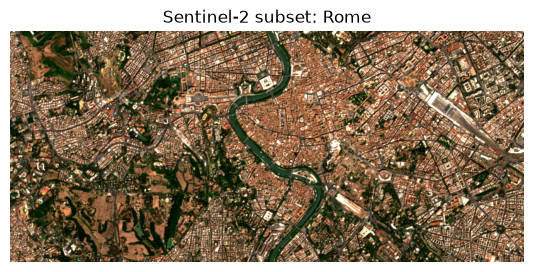

In [17]:
s2_subset = save_multiband_subset(
    item=s2_item,
    asset_keys=["B04", "B03", "B02"],  # red, green, blue
    bbox_wgs84=rome_bbox,
    output_path="data/raw/sentinel2/s2_rome_rgb_subset.tif",
)

plot_rgb(s2_subset, "Sentinel-2 subset: Rome")